In [1]:
import numpy as np
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
import pandas as pd
from scipy.linalg import expm, eigvals
from matplotlib.lines import Line2D
from itertools import product
import math

In [2]:
# GLOBAL STYLE SETTINGS (run once)

plt.rcParams.update({

    # --- FONT SIZES ---
    "font.size": 24,              # base font size
    "axes.titlesize": 20,         # title
    "axes.labelsize": 36,         # x/y labels
    "xtick.labelsize": 36,
    "ytick.labelsize": 36,
    "legend.fontsize": 16,

    # --- LINES ---
    "lines.linewidth": 5,
    "lines.markersize": 16,

    # --- FIGURE / AXIS ---
    "figure.figsize": (8, 6),
    "figure.dpi": 120,
    "axes.linewidth": 1.5,        # thicker axis spines

    # --- TICKS ---
    "xtick.major.size": 15,
    "xtick.major.width": 3,
    "ytick.major.size": 15,
    "ytick.major.width": 3,

    # --- LEGEND ---
    "legend.frameon": True,
    "legend.framealpha": 0.8,
    "legend.fancybox": True,
})


# L=1

In [5]:
Q=4

def compete_4(tau, nu, dt, PopSize=10**8, steps=1000):
    # --- Helper: TR/VR pairs ---
    pairs = np.array([(i,) for i in range(4)])  # 4 pairs

    # --- Initialize population: evenly across TR×VR, all DGR=off ---
    Pop = np.full(4, PopSize // 4, dtype=np.int64)
    Pop[0] += PopSize - Pop.sum()  # Give leftover to (TR=0, VR=0, DGR=0)

    # --- Precompute H for all possible environments ---
    all_envs = np.array([(i,) for i in range(4)])
    # --- Initialize environment and tracking ---
    env = (0,)
    H = np.zeros(4)
    for idx, (x,) in enumerate(pairs):
        H[idx] =  (1 if x == env[0] else 0)
    next_switch = tau / dt
    AvH = np.zeros(steps)

    for k in range(steps):
        # ---- Environment switch ----
        if k > next_switch:
            env=((env[0]+np.random.randint(1,4))%4,)
            H = np.zeros(4)
            for idx, (x,) in enumerate(pairs):
                H[idx] =  (1 if x == env[0] else 0) 
            next_switch += tau / dt
        # ---- SELECTION / REPRODUCTION ----
        w = np.exp(H * dt)
        total_fit = np.dot(Pop, w)
        if total_fit <= 0:
            P_repro = np.ones(4) / 4
        else:
            P_repro = Pop * w / total_fit
        Pop = np.random.multinomial(PopSize, P_repro)

        # ---- VR SWITCHING (only for DGR=on) ----
        if nu * dt > 0:
            s = np.random.binomial(Pop, nu * dt)
            Pop -= s
            Pop += np.random.multinomial(s.sum(), [1/4] * 4)

        # ---- Statistics ----
        AvH[k] = np.dot(Pop, H) / PopSize

    # Discard initial transient (3 environment periods)
    cut = 3 * int(tau / dt)
    return np.mean(AvH[cut:])

10
1e-05
5.550473077848113e-05
0.0003080775138791673
0.001709975946676698
0.009491175455796853
0.05268051384453322
0.29240177382128696
1.6229681735100865
9.008241153272058
49.99999999999999
20
1e-05
5.550473077848113e-05
0.0003080775138791673
0.001709975946676698
0.009491175455796853
0.05268051384453322
0.29240177382128696
1.6229681735100865
9.008241153272058
49.99999999999999
30
1e-05
5.550473077848113e-05
0.0003080775138791673
0.001709975946676698
0.009491175455796853
0.05268051384453322
0.29240177382128696
1.6229681735100865
9.008241153272058
49.99999999999999
40
1e-05
5.550473077848113e-05
0.0003080775138791673
0.001709975946676698
0.009491175455796853
0.05268051384453322
0.29240177382128696
1.6229681735100865
9.008241153272058
49.99999999999999


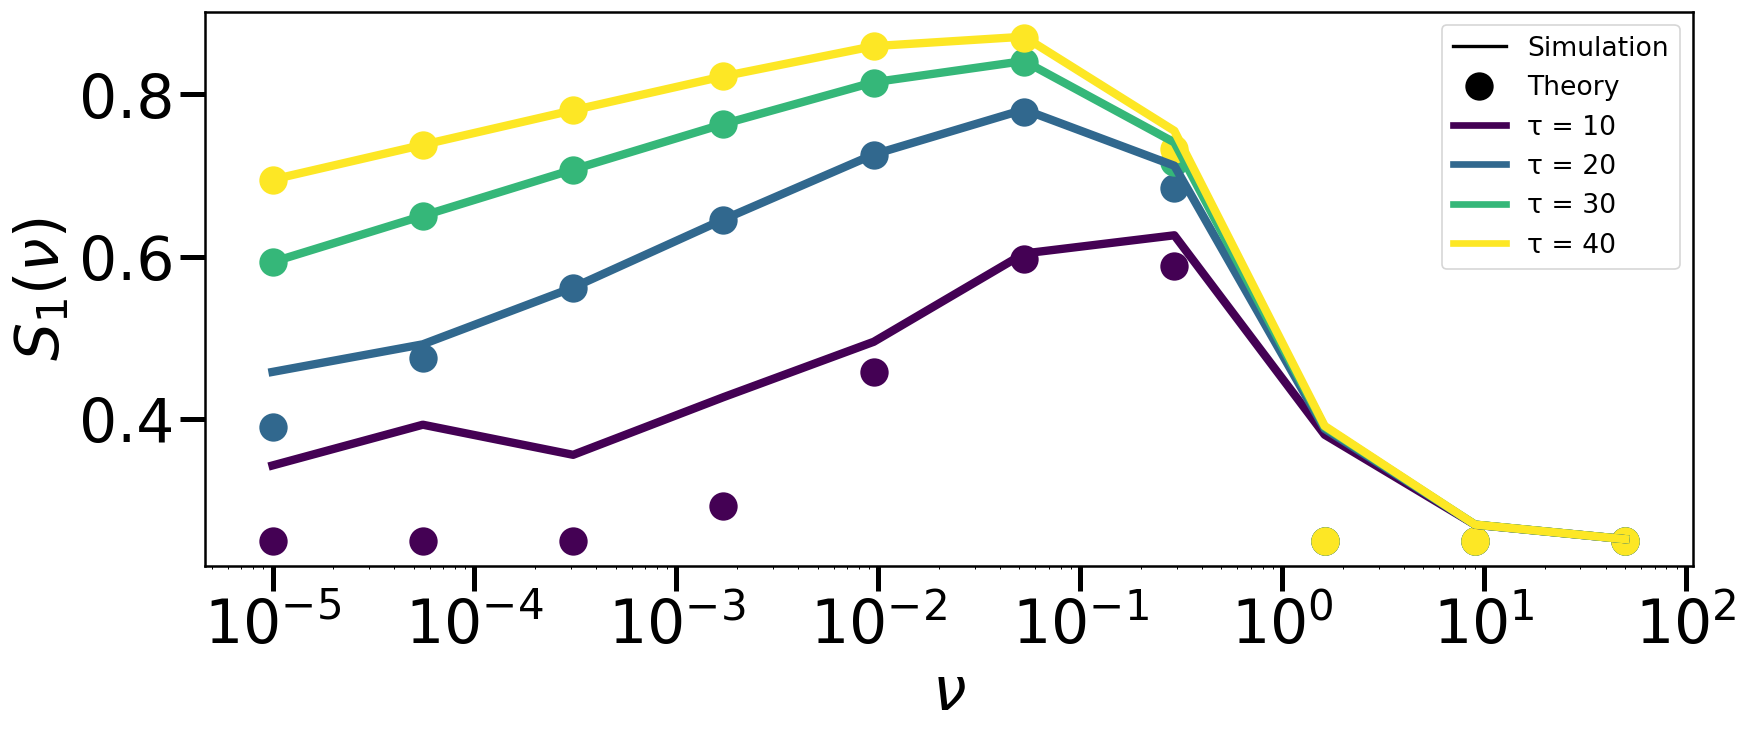

In [6]:
dt=1e-2
L=1

nu_lis=np.logspace(-5,np.log10(50),10)
tau_lis=[10,20,30,40]
colors = plt.cm.viridis(np.linspace(0, 1, len(tau_lis)))
k=0

def growth_for_nu_list( 
    tau, nu_list,  dt,
        PopSize=10**12,
        steps=40000,
    n_jobs=-1):
    results = Parallel(n_jobs=n_jobs)(
        delayed(compete_4)(tau, nu, dt,
        PopSize,
        steps) for nu in nu_list
    )
    return results

plt.figure(figsize=(16,6))
for tau in tau_lis:
    print(tau)
    S=growth_for_nu_list(tau, nu_lis, dt,
        PopSize=10**12,
        steps=int(tau/dt*60))
    S_theo=[]
    
    for nu in nu_lis:
        print(nu)
        S_theo.append(max(L/Q,L-nu*(1-Q**(-L))+np.log(2*nu/Q**L/L)/tau))
    plt.plot(nu_lis,S,color=colors[k])
    plt.scatter(nu_lis,S_theo,label=f'τ = {tau}',color=colors[k])
    k+=1
# --- Custom legend ---
legend_lines = [Line2D([0], [0], color='k', lw=2, label='Simulation'),
                Line2D([0], [0], marker='o', color='w', markerfacecolor='k',
                       markeredgecolor='k', label='Theory')]

tau_handles = [Line2D([0], [0], color=color, lw=4, label=f'τ = {tau}') for color, tau in zip(colors, tau_lis)]


plt.xlabel(r"$\nu$")
plt.ylabel(r"$S_1(\nu)$")
plt.semilogx()
plt.legend(handles=legend_lines + tau_handles)
plt.savefig('Effective_Growth_VR_stochastic_L=1.svg')

# L=2

In [7]:
def compete_16(tau, nu, dt, PopSize=10**8, steps=1000):
    # --- Helper: TR/VR pairs ---
    pairs = np.array([(i, j) for i in range(4) for j in range(4)])  # 256 pairs

    # --- Initialize population: evenly across TR×VR, all DGR=off ---
    Pop = np.full(16, PopSize // 16, dtype=np.int64)
    Pop[0] += PopSize - Pop.sum()  # Give leftover to (TR=0, VR=0, DGR=0)

    # --- Precompute H for all possible environments ---
    all_envs = np.array([(i, j) for i in range(4) for j in range(4)])
    # --- Initialize environment and tracking ---
    env = (0, 0)
    H = np.zeros(16)
    for idx, (x, y) in enumerate(pairs):
        H[idx] =  (1 if x == env[0] else 0) + (1 if y == env[1] else 0)
    next_switch = tau / dt
    AvH = np.zeros(steps)

    for k in range(steps):
        # ---- Environment switch ----
        if k > next_switch:
            env=((env[0]+np.random.randint(1,4))%4,(env[1]+np.random.randint(1,4))%4)
            H = np.zeros(16)
            for idx, (x, y) in enumerate(pairs):
                H[idx] =  (1 if x == env[0] else 0) + (1 if y == env[1] else 0)
            next_switch += tau / dt
        # ---- SELECTION / REPRODUCTION ----
        w = np.exp(H * dt)
        total_fit = np.dot(Pop, w)
        if total_fit <= 0:
            P_repro = np.ones(16) / 16
        else:
            P_repro = Pop * w / total_fit
        Pop = np.random.multinomial(PopSize, P_repro)

        # ---- VR SWITCHING (only for DGR=on) ----
        if nu * dt > 0:
            s = np.random.binomial(Pop, nu * dt)
            Pop -= s
            Pop += np.random.multinomial(s.sum(), [1/16] * 16)

        # ---- Statistics ----
        AvH[k] = np.dot(Pop, H) / PopSize

    # Discard initial transient (3 environment periods)
    cut = 3 * int(tau / dt)
    return np.mean(AvH[cut:])

10
1e-05
5.550473077848113e-05
0.0003080775138791673
0.001709975946676698
0.009491175455796853
0.05268051384453322
0.29240177382128696
1.6229681735100865
9.008241153272058
49.99999999999999
20
1e-05
5.550473077848113e-05
0.0003080775138791673
0.001709975946676698
0.009491175455796853
0.05268051384453322
0.29240177382128696
1.6229681735100865
9.008241153272058
49.99999999999999
30
1e-05
5.550473077848113e-05
0.0003080775138791673
0.001709975946676698
0.009491175455796853
0.05268051384453322
0.29240177382128696
1.6229681735100865
9.008241153272058
49.99999999999999
40
1e-05
5.550473077848113e-05
0.0003080775138791673
0.001709975946676698
0.009491175455796853
0.05268051384453322
0.29240177382128696
1.6229681735100865
9.008241153272058
49.99999999999999


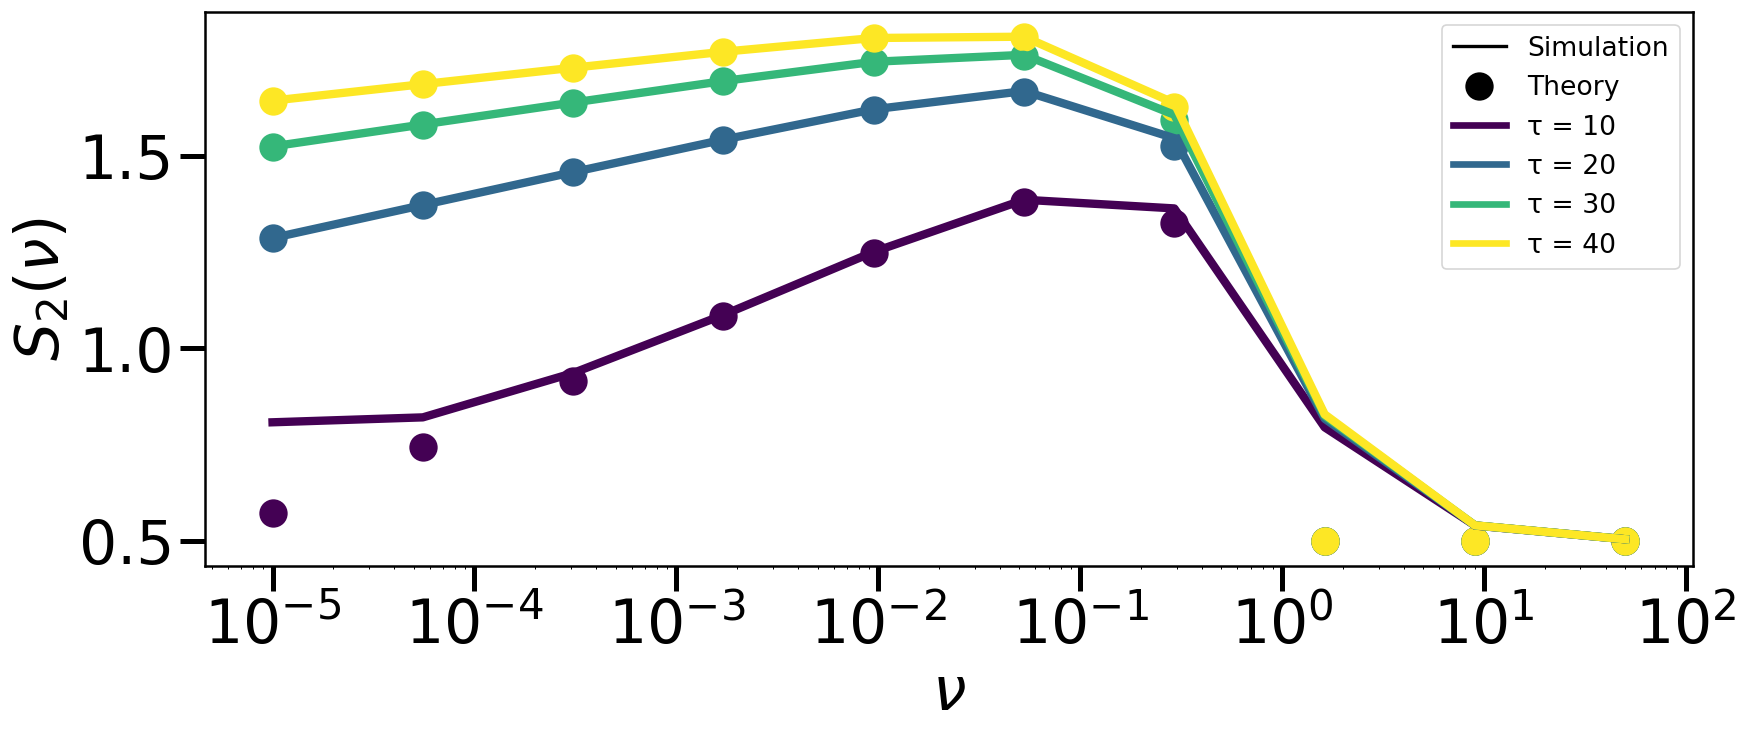

In [8]:
dt=1e-2
L=2

nu_lis=np.logspace(-5,np.log10(50),10)
tau_lis=[10,20,30,40]
colors = plt.cm.viridis(np.linspace(0, 1, len(tau_lis)))
k=0

def growth_for_nu_list( 
    tau, nu_list,  dt,
        PopSize=10**12,
        steps=40000,
    n_jobs=-1):
    results = Parallel(n_jobs=n_jobs)(
        delayed(compete_16)(tau, nu, dt,
        PopSize,
        steps) for nu in nu_list
    )
    return results

plt.figure(figsize=(16,6))
for tau in tau_lis:
    print(tau)
    S=growth_for_nu_list(tau, nu_lis, dt,
        PopSize=10**12,
        steps=int(tau/dt*40))
    S_theo=[]
    
    for nu in nu_lis:
        print(nu)
        S_theo.append(max(L/Q,L-nu*(1-Q**(-L))+np.log(2*nu/Q**L/L)/tau))
    plt.plot(nu_lis,S,color=colors[k])
    plt.scatter(nu_lis,S_theo,label=f'τ = {tau}',color=colors[k])
    k+=1
# --- Custom legend ---
legend_lines = [Line2D([0], [0], color='k', lw=2, label='Simulation'),
                Line2D([0], [0], marker='o', color='w', markerfacecolor='k',
                       markeredgecolor='k', label='Theory')]

tau_handles = [Line2D([0], [0], color=color, lw=4, label=f'τ = {tau}') for color, tau in zip(colors, tau_lis)]


plt.xlabel(r"$\nu$")
plt.ylabel(r"$S_2(\nu)$")
plt.semilogx()
plt.legend(handles=legend_lines + tau_handles)
plt.savefig('Effective_Growth_VR_stochastic_L=2.svg')

# L=4

In [9]:


def compete_256(tau, nu, dt, PopSize=10**8, steps=1000):
    # --- Helper: TR/VR pairs ---
    pairs = np.array([(i, j, k, l) for i in range(4) for j in range(4) for k in range(4) for l in range(4)])  # 256 pairs

    # --- Initialize population: evenly across TR×VR, all DGR=off ---
    Pop = np.full(256, PopSize // 256, dtype=np.int64)
    Pop[0] += PopSize - Pop.sum()  # Give leftover to (TR=0, VR=0, DGR=0)

    # --- Precompute H for all possible environments ---
    all_envs = np.array([(i, j, k, l) for i in range(4) for j in range(4) for k in range(4) for l in range(4)])
    # --- Initialize environment and tracking ---
    env = (0, 0, 0, 0)
    H = np.zeros(256)
    for idx, (x, y,z,a) in enumerate(pairs):
        H[idx] =  (1 if x == env[0] else 0) + (1 if y == env[1] else 0)+(1 if z == env[2] else 0) + (1 if a == env[3] else 0)
    next_switch = tau / dt
    AvH = np.zeros(steps)

    for k in range(steps):
        # ---- Environment switch ----
        if k > next_switch:
            env=((env[0]+np.random.randint(1,4))%4,(env[1]+np.random.randint(1,4))%4,(env[2]+np.random.randint(1,4))%4,(env[3]+np.random.randint(1,4))%4)
            H = np.zeros(256)
            for idx, (x, y,z,a) in enumerate(pairs):
                H[idx] =  (1 if x == env[0] else 0) + (1 if y == env[1] else 0)+(1 if z == env[2] else 0) + (1 if a == env[3] else 0)
            next_switch += tau / dt
        # ---- SELECTION / REPRODUCTION ----
        w = np.exp(H * dt)
        total_fit = np.dot(Pop, w)
        if total_fit <= 0:
            P_repro = np.ones(256) / 256
        else:
            P_repro = Pop * w / total_fit
        Pop = np.random.multinomial(PopSize, P_repro)

        # ---- VR SWITCHING (only for DGR=on) ----
        if nu * dt > 0:
            s = np.random.binomial(Pop, nu * dt)
            Pop -= s
            Pop += np.random.multinomial(s.sum(), [1/256] * 256)

        # ---- Statistics ----
        AvH[k] = np.dot(Pop, H) / PopSize

    # Discard initial transient (3 environment periods)
    cut = 3 * int(tau / dt)
    return np.mean(AvH[cut:])

10
1e-05
5.550473077848113e-05
0.0003080775138791673
0.001709975946676698
0.009491175455796853
0.05268051384453322
0.29240177382128696
1.6229681735100865
9.008241153272058
49.99999999999999
20
1e-05
5.550473077848113e-05
0.0003080775138791673
0.001709975946676698
0.009491175455796853
0.05268051384453322
0.29240177382128696
1.6229681735100865
9.008241153272058
49.99999999999999
30
1e-05
5.550473077848113e-05
0.0003080775138791673
0.001709975946676698
0.009491175455796853
0.05268051384453322
0.29240177382128696
1.6229681735100865
9.008241153272058
49.99999999999999
40
1e-05
5.550473077848113e-05
0.0003080775138791673
0.001709975946676698
0.009491175455796853
0.05268051384453322
0.29240177382128696
1.6229681735100865
9.008241153272058
49.99999999999999


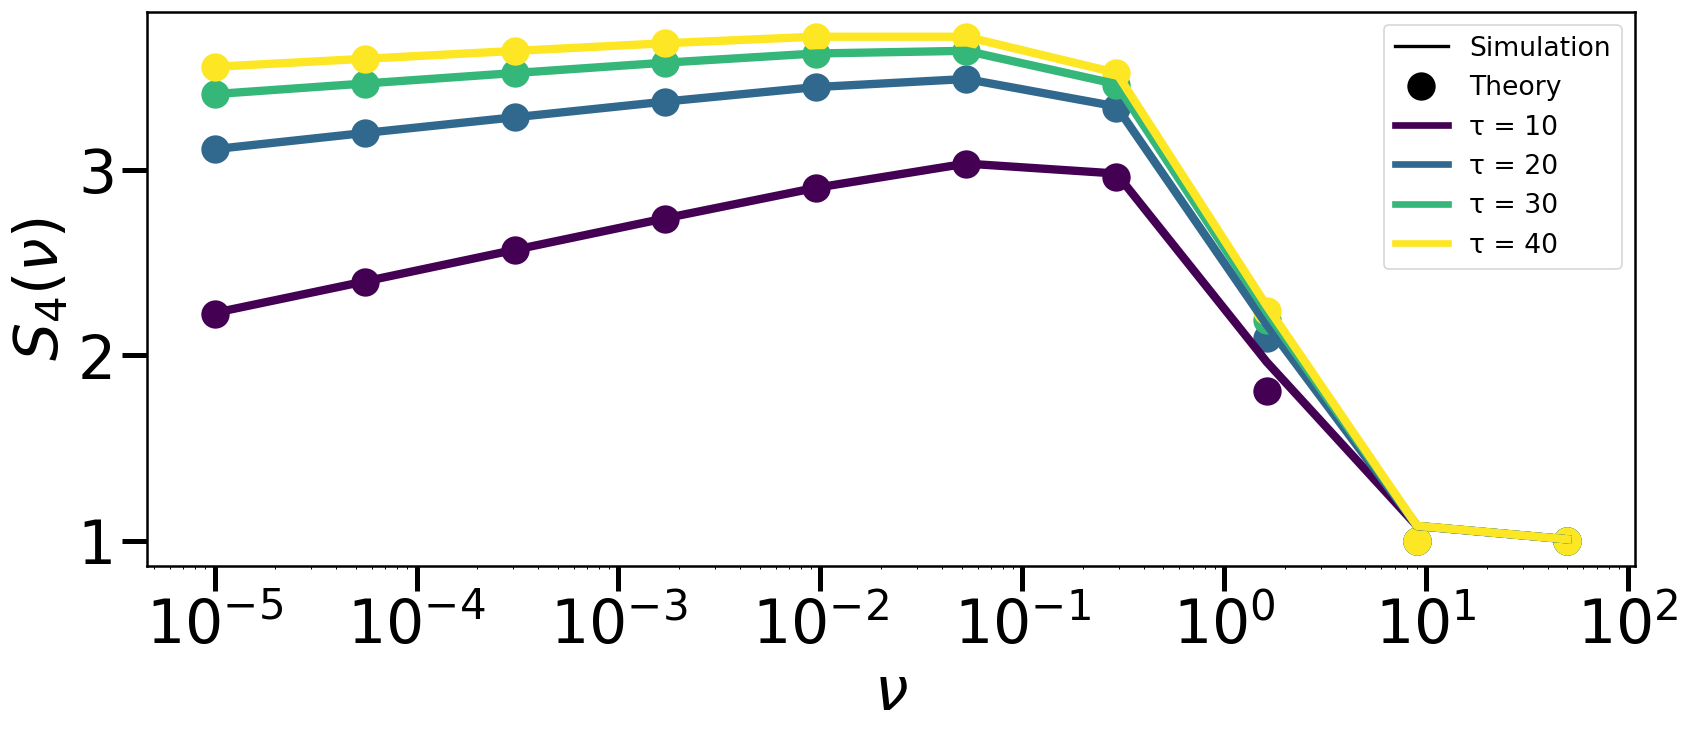

In [10]:

dt=1e-2
L=4

nu_lis=np.logspace(-5,np.log10(50),10)
tau_lis=[10,20,30,40]
colors = plt.cm.viridis(np.linspace(0, 1, len(tau_lis)))
k=0

def growth_for_nu_list( 
    tau, nu_list,  dt,
        PopSize=10**12,
        steps=40000,
    n_jobs=-1):
    results = Parallel(n_jobs=n_jobs)(
        delayed(compete_256)(tau, nu, dt,
        PopSize,
        steps) for nu in nu_list
    )
    return results

plt.figure(figsize=(16,6))
for tau in tau_lis:
    print(tau)
    S=growth_for_nu_list(tau, nu_lis, dt,
        PopSize=10**12,
        steps=int(tau/dt*10))
    S_theo=[]
    
    for nu in nu_lis:
        print(nu)
        S_theo.append(max(L/Q,L-nu*(1-Q**(-L))+np.log(2*nu/Q**L/L)/tau))
    plt.plot(nu_lis,S,color=colors[k])
    plt.scatter(nu_lis,S_theo,label=f'τ = {tau}',color=colors[k])
    k+=1
# --- Custom legend ---
legend_lines = [Line2D([0], [0], color='k', lw=2, label='Simulation'),
                Line2D([0], [0], marker='o', color='w', markerfacecolor='k',
                       markeredgecolor='k', label='Theory')]

tau_handles = [Line2D([0], [0], color=color, lw=4, label=f'τ = {tau}') for color, tau in zip(colors, tau_lis)]


plt.xlabel(r"$\nu$")
plt.ylabel(r"$S_4(\nu)$")
plt.semilogx()
plt.legend(handles=legend_lines + tau_handles)
plt.savefig('Effective_Growth_VR_stochastic_L=4.svg')